# 05 - Walk-Forward Evaluation

Walk-forward pseudo-live evaluation using fixed parameters.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path().resolve()
CANDIDATES = [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]
PROJECT_ROOT = None
for candidate in CANDIDATES:
    if (candidate / 'src' / '__init__.py').exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise RuntimeError('Unable to locate project root containing src/__init__.py')

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.walk_forward import generate_rolling_windows, walk_forward_fixed_params, walk_forward_retrained_params
from src.metrics import sharpe_ratio, max_drawdown, sharpe_confidence_interval, buy_and_hold_metrics

plt.style.use('seaborn-v0_8')

## Load processed 5-minute data

In [2]:
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'btcusdt_5m.parquet'
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Missing processed parquet at {DATA_PATH}')

df = pd.read_parquet(DATA_PATH)
df = df.dropna(subset=['log_return']).sort_index()
print(f'Rows: {len(df):,} from {df.index.min()} to {df.index.max()}')
df.head()


Rows: 105,407 from 2024-01-01 00:05:00+00:00 to 2024-12-31 23:55:00+00:00


,open,high,low,close,volume,return,log_return
timestamp,,,,,,,
2024-01-01 00:05:00+00:00,42397.22,42432.74,42385.26,42409.96,141.311,0.000300,0.000300
2024-01-01 00:10:00+00:00,42409.97,42488.09,42409.96,42488.00,135.143,0.001840,0.001838
2024-01-01 00:15:00+00:00,42488.00,42554.57,42458.58,42458.85,163.324,-0.000686,-0.000686
2024-01-01 00:20:00+00:00,42458.85,42491.10,42445.84,42473.93,117.272,0.000355,0.000355
2024-01-01 00:25:00+00:00,42473.93,42500.00,42412.02,42419.73,111.651,-0.001276,-0.001277


## Generate rolling windows

In [3]:
WINDOW_TRAIN_DAYS = 60
WINDOW_TEST_DAYS = 10

windows = generate_rolling_windows(
    df,
    train_days=WINDOW_TRAIN_DAYS,
    test_days=WINDOW_TEST_DAYS,
)
print(f'Generated {len(windows)} windows')
if windows:
    print(windows[0])

Generated 31 windows
WindowSpec(train_start=Timestamp('2024-01-01 00:00:00+0000', tz='UTC'), train_end=Timestamp('2024-02-29 23:59:59+0000', tz='UTC'), test_start=Timestamp('2024-03-01 00:00:00+0000', tz='UTC'), test_end=Timestamp('2024-03-10 23:59:59+0000', tz='UTC'))


## Run fixed-parameter walk-forward

In [4]:
WINDOW = 20
Z_ENTRY = 1.5
COST_PER_UNIT = 0.0005

wf_result = walk_forward_fixed_params(
    df=df,
    windows=windows,
    window_param=WINDOW,
    z_entry_param=Z_ENTRY,
    cost_per_unit_change=COST_PER_UNIT,
)

test_returns = wf_result['test_returns']
test_equity = wf_result['test_equity_curve']
per_window_metrics = wf_result['per_window_metrics']

print(f'Total test bars: {len(test_returns):,}')
test_equity.tail()

Total test bars: 88,128


timestamp
2024-12-31 23:35:00+00:00    0.000026
2024-12-31 23:40:00+00:00    0.000026
2024-12-31 23:45:00+00:00    0.000026
2024-12-31 23:50:00+00:00    0.000026
2024-12-31 23:55:00+00:00    0.000026
Name: strategy_return_net, dtype: float64

## Pseudo-live metrics

In [5]:
sharpe_wf = sharpe_ratio(test_returns)
ci_wf     = sharpe_confidence_interval(test_returns)
dd_wf     = max_drawdown(test_equity)
total_return = test_equity.iloc[-1] / test_equity.iloc[0] - 1.0

bh = buy_and_hold_metrics(df)

print(f'Walk-forward Sharpe (net):            {sharpe_wf:.3f}')
print(f'Walk-forward Sharpe 95% CI:           ({ci_wf[0]:.3f}, {ci_wf[1]:.3f})')
print(f'Walk-forward max drawdown (net):      {dd_wf:.2%}')
print(f'Walk-forward cumulative return (net): {total_return:.2%}')
print()
print(f'Buy-and-hold Sharpe (full year):      {bh["sharpe"]:.3f}')
print(f'Buy-and-hold max drawdown:            {bh["max_drawdown"]:.2%}')
print(f'Buy-and-hold total return:            {bh["total_return"]:.2%}')

Walk-forward Sharpe (net):            -50.458
Walk-forward Sharpe 95% CI:           (-53.996, -47.104)
Walk-forward max drawdown (net):      -100.00%
Walk-forward cumulative return (net): -100.00%

Buy-and-hold Sharpe (full year):      1.470
Buy-and-hold max drawdown:            -32.99%
Buy-and-hold total return:            120.71%


## Equity curve

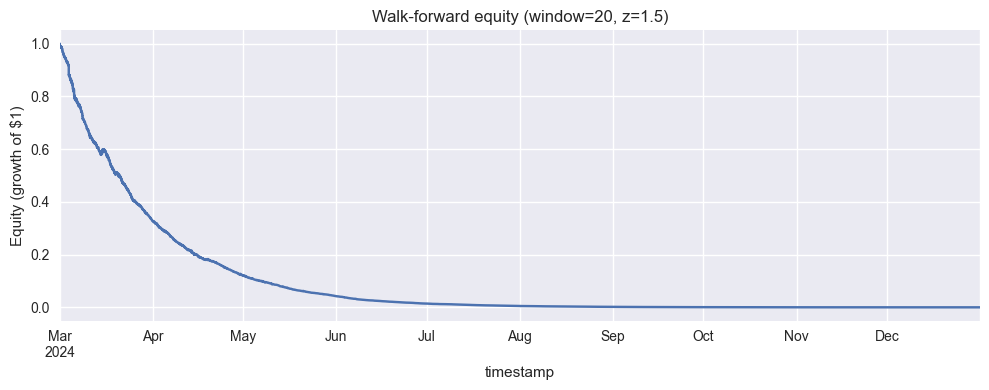

In [6]:
ax = test_equity.plot(figsize=(10, 4), title=f'Walk-forward equity (window={WINDOW}, z={Z_ENTRY})')
ax.set_ylabel('Equity (growth of $1)')
ax.grid(True)
plt.tight_layout()
plt.show()

## Per-window metrics

In [7]:
df_windows = pd.DataFrame(per_window_metrics)
df_windows

,train_start,train_end,test_start,test_end,test_sharpe,test_max_dd,test_net_return,test_cum_return,test_trades,test_total_cost
0,2024-01-01 00:00:00+00:00,2024-02-29 23:59:59+00:00,2024-03-01 00:00:00+00:00,2024-03-10 23:59:59+00:00,-43.117971,-0.348914,-0.429113,-0.348914,664,0.3480
1,2024-01-11 00:00:00+00:00,2024-03-10 23:59:59+00:00,2024-03-11 00:00:00+00:00,2024-03-20 23:59:59+00:00,-29.032917,-0.246097,-0.269226,-0.236029,685,0.3580
2,2024-01-21 00:00:00+00:00,2024-03-20 23:59:59+00:00,2024-03-21 00:00:00+00:00,2024-03-30 23:59:59+00:00,-61.307303,-0.312682,-0.374959,-0.312682,660,0.3430
3,2024-01-31 00:00:00+00:00,2024-03-30 23:59:59+00:00,2024-03-31 00:00:00+00:00,2024-04-09 23:59:59+00:00,-59.685069,-0.298346,-0.352774,-0.297264,662,0.3500
4,2024-02-10 00:00:00+00:00,2024-04-09 23:59:59+00:00,2024-04-10 00:00:00+00:00,2024-04-19 23:59:59+00:00,-31.392971,-0.263195,-0.302915,-0.261338,623,0.3290
5,2024-02-20 00:00:00+00:00,2024-04-19 23:59:59+00:00,2024-04-20 00:00:00+00:00,2024-04-29 23:59:59+00:00,-64.223223,-0.297121,-0.349248,-0.294782,610,0.3210
6,2024-03-01 00:00:00+00:00,2024-04-29 23:59:59+00:00,2024-04-30 00:00:00+00:00,2024-05-09 23:59:59+00:00,-45.574420,-0.281894,-0.315841,-0.270825,644,0.3390
7,2024-03-11 00:00:00+00:00,2024-05-09 23:59:59+00:00,2024-05-10 00:00:00+00:00,2024-05-19 23:59:59+00:00,-67.526289,-0.309671,-0.370587,-0.309671,646,0.3395
8,2024-03-21 00:00:00+00:00,2024-05-19 23:59:59+00:00,2024-05-20 00:00:00+00:00,2024-05-29 23:59:59+00:00,-58.671697,-0.264556,-0.307281,-0.264556,618,0.3250
9,2024-03-31 00:00:00+00:00,2024-05-29 23:59:59+00:00,2024-05-30 00:00:00+00:00,2024-06-08 23:59:59+00:00,-80.659761,-0.362144,-0.449458,-0.362026,682,0.3630


## Walk-forward with per-window parameter selection

In [8]:
CANDIDATE_WINDOWS = [10, 20, 40]
CANDIDATE_Z_ENTRIES = [1.0, 1.5, 2.0]

wf_opt = walk_forward_retrained_params(
    df=df,
    windows=windows,
    candidate_windows=CANDIDATE_WINDOWS,
    candidate_z_entries=CANDIDATE_Z_ENTRIES,
    cost_per_unit_change=COST_PER_UNIT,
)

opt_returns = wf_opt['test_returns']
opt_equity = wf_opt['test_equity_curve']
opt_metrics = pd.DataFrame(wf_opt['per_window_metrics'])

opt_sharpe = sharpe_ratio(opt_returns)
opt_ci     = sharpe_confidence_interval(opt_returns)

print(f'Optimised walk-forward Sharpe (net):   {opt_sharpe:.3f}')
print(f'Optimised walk-forward Sharpe 95% CI: ({opt_ci[0]:.3f}, {opt_ci[1]:.3f})')
print(f'Optimised walk-forward max DD (net):   {max_drawdown(opt_equity):.2%}')
print(f'Optimised walk-forward cum. return:    {opt_equity.iloc[-1] / opt_equity.iloc[0] - 1.0:.2%}')
print()
print(f'Fixed-param Sharpe:                    {sharpe_wf:.3f}  |  CI: ({ci_wf[0]:.3f}, {ci_wf[1]:.3f})')

Optimised walk-forward Sharpe (net):   -27.026
Optimised walk-forward Sharpe 95% CI: (-30.272, -24.067)
Optimised walk-forward max DD (net):   -98.68%
Optimised walk-forward cum. return:    -98.68%

Fixed-param Sharpe:                    -50.458  |  CI: (-53.996, -47.104)


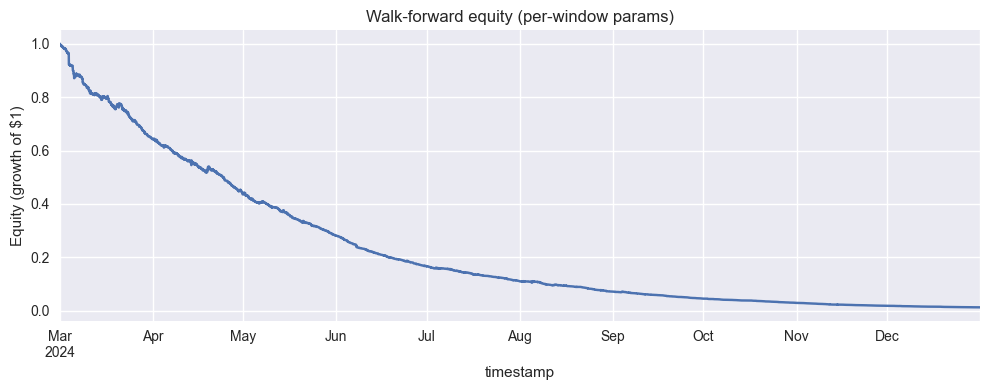

,train_start,train_end,test_start,test_end,chosen_window,chosen_z_entry,test_sharpe,test_max_dd,test_net_return,test_cum_return,test_trades,test_total_cost
0,2024-01-01 00:00:00+00:00,2024-02-29 23:59:59+00:00,2024-03-01 00:00:00+00:00,2024-03-10 23:59:59+00:00,20,2.0,-24.793438,-0.178927,-0.197144,-0.178927,227,0.1180
1,2024-01-11 00:00:00+00:00,2024-03-10 23:59:59+00:00,2024-03-11 00:00:00+00:00,2024-03-20 23:59:59+00:00,20,2.0,-9.905445,-0.083719,-0.063778,-0.061787,275,0.1400
2,2024-01-21 00:00:00+00:00,2024-03-20 23:59:59+00:00,2024-03-21 00:00:00+00:00,2024-03-30 23:59:59+00:00,20,2.0,-40.391089,-0.159755,-0.167526,-0.154245,280,0.1420
3,2024-01-31 00:00:00+00:00,2024-03-30 23:59:59+00:00,2024-03-31 00:00:00+00:00,2024-04-09 23:59:59+00:00,20,2.0,-32.553596,-0.115281,-0.122319,-0.115134,266,0.1330
4,2024-02-10 00:00:00+00:00,2024-04-09 23:59:59+00:00,2024-04-10 00:00:00+00:00,2024-04-19 23:59:59+00:00,20,2.0,-10.680485,-0.101593,-0.081859,-0.078598,272,0.1400
5,2024-02-20 00:00:00+00:00,2024-04-19 23:59:59+00:00,2024-04-20 00:00:00+00:00,2024-04-29 23:59:59+00:00,40,2.0,-37.347820,-0.159516,-0.163728,-0.151027,293,0.1520
6,2024-03-01 00:00:00+00:00,2024-04-29 23:59:59+00:00,2024-04-30 00:00:00+00:00,2024-05-09 23:59:59+00:00,40,2.0,-25.016531,-0.136181,-0.139491,-0.130199,289,0.1490
7,2024-03-11 00:00:00+00:00,2024-05-09 23:59:59+00:00,2024-05-10 00:00:00+00:00,2024-05-19 23:59:59+00:00,40,2.0,-34.334399,-0.141538,-0.152613,-0.141538,278,0.1455
8,2024-03-21 00:00:00+00:00,2024-05-19 23:59:59+00:00,2024-05-20 00:00:00+00:00,2024-05-29 23:59:59+00:00,40,2.0,-36.529951,-0.133151,-0.142890,-0.133151,283,0.1450
9,2024-03-31 00:00:00+00:00,2024-05-29 23:59:59+00:00,2024-05-30 00:00:00+00:00,2024-06-08 23:59:59+00:00,40,2.0,-45.504123,-0.195684,-0.217763,-0.195684,293,0.1540


In [9]:
ax = opt_equity.plot(figsize=(10, 4), title='Walk-forward equity (per-window params)')
ax.set_ylabel('Equity (growth of $1)')
ax.grid(True)
plt.tight_layout()
plt.show()

opt_metrics